# 1- Customer Data

### Hum is data ke saath kya karne ja rahe hain?
Is section mein hum **ShopEasy** company ke customers ka data analyze aur clean karenge. Hamara maqsad yeh dekhna hai ke:
1. Customers ka data sahi format mein load ho raha hai ya nahi.
2. Data ka size kitna hai (Rows aur Columns).
3. Kya data mein koi duplicate records ya khali (Missing/Null) values hain jo hamari analysis ko kharab kar sakti hain.
4. Customers ki demographics (Gender aur Age) ki distribution kaisi hai.

In [10]:
# Sab se pehle zaroori libraries import kar rahe hain: Data manipulation ke liye Pandas, aur graphs banane ke liye Matplotlib aur Seaborn.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
# Excel file Load Karna or  customers ka data read kar ke use 'customers' naam ke variable (DataFrame) mein save karna
customers = pd.read_excel("customers.xlsx")
customers

,CustomerID,CustomerName,Email,Gender,Age,GeographyID
0,1,Emma Anderson,emma.anderson@example.com,Male,50,2
1,2,Sarah Brown,sarah.brown@example.com,Female,37,4
2,3,Robert Hernandez,robert.hernandez@example.com,Female,26,6
3,4,David Garcia,david.garcia@example.com,Male,25,8
4,5,Emma Miller,emma.miller@example.com,Female,41,4
...,...,...,...,...,...,...
95,96,Emily Gonzalez,emily.gonzalez@example.com,Female,38,10
96,97,Emily Rodriguez,emily.rodriguez@example.com,Female,51,3
97,98,Chris Lopez,chris.lopez@example.com,Female,55,10
98,99,Laura Hernandez,laura.hernandez@example.com,Male,41,5


In [12]:
# Data ka structure mtlb size check karna ke isme total kitni rows (customers) aur kitne columns hain
customers.shape

(100, 6)

In [13]:
# Har column ka naam, usme kitni non-null values hain aur unki data type (Text, Number, etc.) check karna
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   CustomerID    100 non-null    int64 
 1   CustomerName  100 non-null    object
 2   Email         100 non-null    object
 3   Gender        100 non-null    object
 4   Age           100 non-null    int64 
 5   GeographyID   100 non-null    int64 
dtypes: int64(3), object(3)
memory usage: 4.8+ KB


In [14]:
# Duplicate Data Dhoondna
# Yeh check karna ke koi customer do baar ya baar-baar repeat toh nahi ho raha (Duplicates count)
customers.duplicated().sum()

np.int64(0)

In [15]:
# Khali (Missing) Jaghein Check Karna
# Yeh dekhna ke kis column mein data missing (NaN/Null) hai, taake hum use baad mein fix kar sakein
customers.isna().sum()

CustomerID      0
CustomerName    0
Email           0
Gender          0
Age             0
GeographyID     0
dtype: int64

In [16]:
# Gender ki Tadaad Check Karna    
# Gender column ka analysis karna ke hamare paas total kitne Male aur kitni Female customers hain
customers.Gender.value_counts()

Gender
Female    54
Male      46
Name: count, dtype: int64

In [17]:
# Age (Umar) ki Details Nikalna
# Customers ki sab se kam (Min), sab se zyada (Max) aur poore data ki average (Mean) umar check karna
customers.Age.min(), customers.Age.max(), customers.Age.mean()

(18, 69, np.float64(41.99))

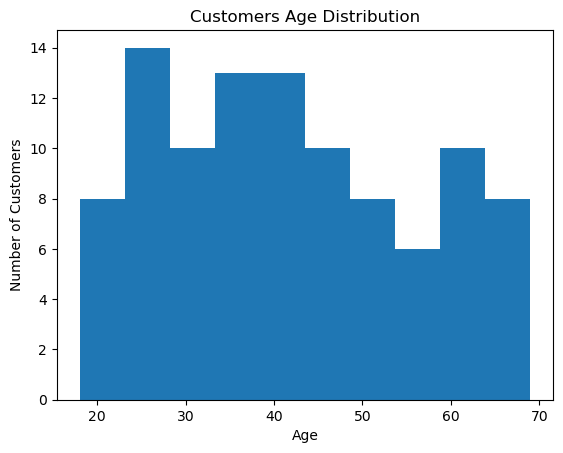

In [18]:
# Age Distribution ka Graph
# Histogram graph banana taake visually dekh sakein ke kis age group ke customers hamare paas sab se zyada hain
plt.hist(customers.Age)
plt.title("Customers Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

In [19]:
#Isse pata chalega ke hamare paas Male customers zyada umar ke hain ya Female customers.
customers.groupby('Gender')['Age'].mean()

Gender
Female    42.981481
Male      40.826087
Name: Age, dtype: float64

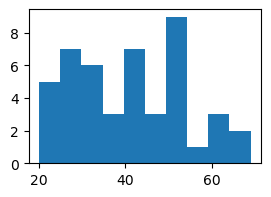

In [20]:
# Yeh graph sirf mardon (Males) ki age distribution dikhayega ke kis umar ke mard zyada shopping kar rahe hain.
plt.figure(figsize=(3,2))
plt.hist(customers[customers.Gender=='Male']['Age'])
plt.show()

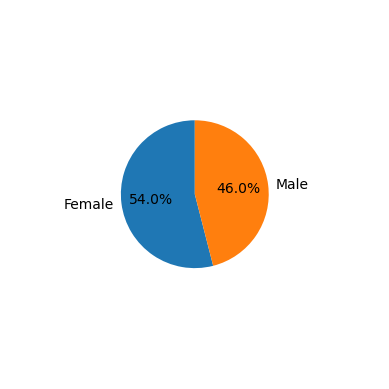

In [21]:
#Is gol chart (Pie Chart) se percentage mein pata chalega ke poore data mein kitne percent mard aur kitne percent khwateen hain.
plt.pie(customers.Gender.value_counts(),
        labels=customers.Gender.value_counts().index,
        autopct="%1.1f%%", startangle=90, radius=0.5)
plt.show()

In [22]:
#Isse hum umar ke hissab se groups bana rahe hain (jaise 18-30 saal ke jawan, 31-40 saal ke log wagera).
customers['Age_Category']=pd.cut(customers.Age,bins=[18,30,40,50,60,70],
                                 labels=['18-30','31-40','41-50','51-60','61-70'])
# Isse pata chalega ke kis age group (category) mein hamare paas sab se zyada customers hain.
Age_Freq = customers.Age_Category.value_counts() #.sort_values(ascending=True)
Age_Freq

Age_Category
31-40    24
18-30    22
41-50    22
51-60    16
61-70    14
Name: count, dtype: int64

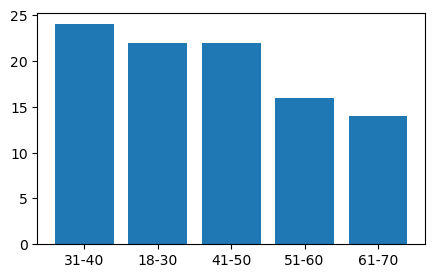

In [23]:
#Yeh khari dandin (Bar Chart) wala graph dikhayega ke kaun sa age group sab se uncha aur bara hai.
plt.figure(figsize=(5,3))
plt.bar(x=Age_Freq.index, height=Age_Freq.values)
plt.show()

In [24]:
# Email se domain (gmail, yahoo, example) alag kar ke naya column banana
customers['Email_Domain'] = customers['Email'].str.split('@').str[1]
customers['Email_Domain'].value_counts()

Email_Domain
example.com    100
Name: count, dtype: int64

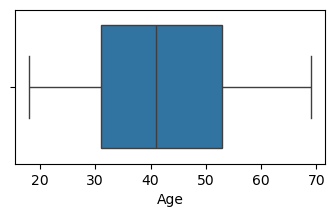

In [25]:
# Boxplot graph banana taake pata chale koi bacha ya bohot zyada burha customer toh nahi hai
plt.figure(figsize=(4,2))
sns.boxplot(x=customers['Age'])
plt.show()

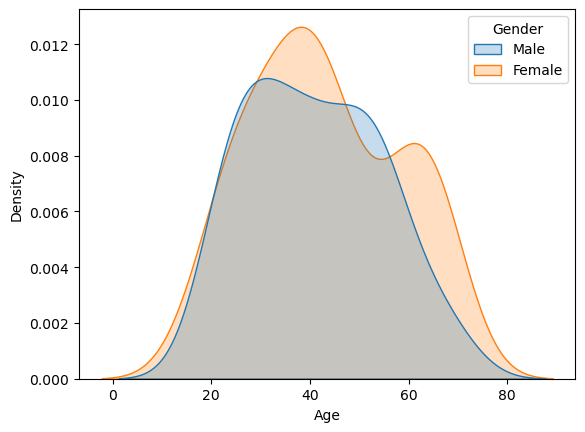

In [26]:
# Male aur Female ki umar ka muqabla karne ke liye ek advanced graph banana
sns.kdeplot(data=customers, x='Age', hue='Gender', fill=True)
plt.show()

In [27]:
# Sab se jawan customers ko upar dekhne ke liye data ko Age ke mutabiq chote se bare (Ascending) order mein lagana
customers.sort_values(by='Age', ascending=True).head()

,CustomerID,CustomerName,Email,Gender,Age,GeographyID,Age_Category,Email_Domain
27,28,Emily Davis,emily.davis@example.com,Female,18,9,NaN,example.com
7,8,James Gonzalez,james.gonzalez@example.com,Female,18,8,NaN,example.com
52,53,Emma Thomas,emma.thomas@example.com,Female,19,2,18-30,example.com
82,83,Emily Jones,emily.jones@example.com,Male,20,9,18-30,example.com
19,20,David Johnson,david.johnson@example.com,Male,22,1,18-30,example.com


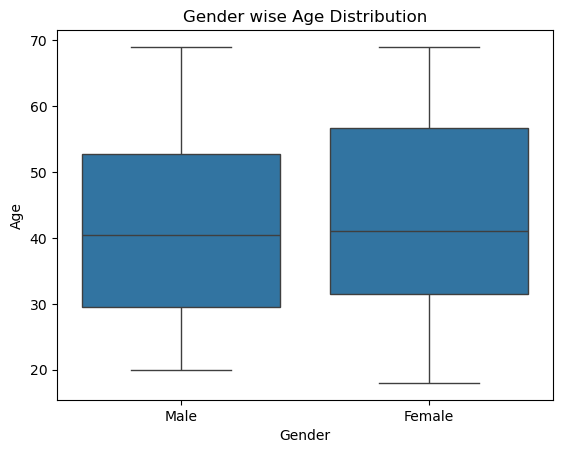

In [28]:
# Ek advanced graph banana jisse pata chale ke Male aur Female customers mein se kiski umar ka group bara hai
import seaborn as sns
sns.boxplot(data=customers, x='Gender', y='Age')
plt.title("Gender wise Age Distribution")
plt.show()

### Summary: Humne is Data ke saath kya kiya?

Is notebook mein humne **ShopEasy** company ke **Customers Data** ka basic analysis kiya hai. Poore kaam ka short khulasa niche diya gaya hai:

1. **Data Load aur Structure Check:**
   * `customers.xlsx` file ko load kiya aur columns ka size (`shape`) aur details (`info`) check ki.

2. **Data Quality Check (Safai):**
   * Data mein duplicates (`duplicated().sum()`) aur khali jagah (`isna().sum()`) check ki taake koi galat data na ho.

3. **Customers Demographics (Tafseelat):**
   * **Gender:** Male aur Female ka count check kiya aur use **Pie Chart** ke zariye percentage mein dikhaya.
   * **Age:** Customers ki minimum, maximum aur average umar nikali, aur **Histogram Graph** se age distribution dekhi.
   * **Gender vs Age:** Gender ke mutabiq average umar nikalne ke liye `groupby` lagaya aur dekha ke kis group ki age zyada hai.

4. **Age Grouping:**
   * Customers ko different age buckets (jaise 18-30, 31-40) mein banta aur use **Bar Chart** ke zariye plot kiya taake sab se bada customer group pata chal sake.

# 2- Customers' Geography Data

Is section mein hum customers ke location (country aur city) ka data load aur analyze karenge.

In [29]:
# Geography ki file ko load karna aur pehli 3 rows dekhna
geography = pd.read_excel("geography.xlsx")
geography.head(3)

,ID,Region,City
0,1,UK,London
1,2,Germany,Berlin
2,3,France,Paris


# 3- Products Data

Is section mein hum **ShopEasy** company ke products (jo saman woh bechte hain) ka data load aur analyze karenge taake products ki categories aur unki quality ka pata chal sake.

In [30]:
# Excel file se products ka data load karna aur pehli 3 rows check karna
products = pd.read_excel("products.xlsx")
products.head(3)

,ProductID,ProductName,Category,Price
0,1,Running Shoes,Sports,223.75
1,2,Fitness Tracker,Sports,196.68
2,3,Yoga Mat,Sports,485.32


In [31]:
# Data mein maujood sabhi unique products ke naam dekhna
products.ProductName.unique()

array(['Running Shoes', 'Fitness Tracker', 'Yoga Mat', 'Dumbbells',
       'Soccer Ball', 'Tennis Racket', 'Basketball', 'Football Helmet',
       'Baseball Glove', 'Golf Clubs', 'Ski Boots', 'Ice Skates',
       'Swim Goggles', 'Cycling Helmet', 'Climbing Rope', 'Kayak',
       'Surfboard', 'Volleyball', 'Hockey Stick', 'Boxing Gloves'],
      dtype=object)

In [32]:
# Yeh dekhna ke hamare paas total kaun-kaun si product categories (jaise Electronics, Clothing etc.) hain
products.Category.unique()

array(['Sports'], dtype=object)

In [33]:
# Check karna ke koi product galti se do baar toh shamil nahi hua
products.duplicated().sum()

np.int64(0)

In [34]:
# Yeh dekhna ke kisi product ka naam, price ya category missing toh nahi hai
products.isna().sum()

ProductID      0
ProductName    0
Category       0
Price          0
dtype: int64

In [35]:
# Total products (rows) aur unki details (columns) ki ginti dekhna
products.shape

(20, 4)

In [36]:
# Har category ke products ki ginti check karna ke kis category mein zyada saman hai
products['Category'].value_counts()

Category
Sports    20
Name: count, dtype: int64

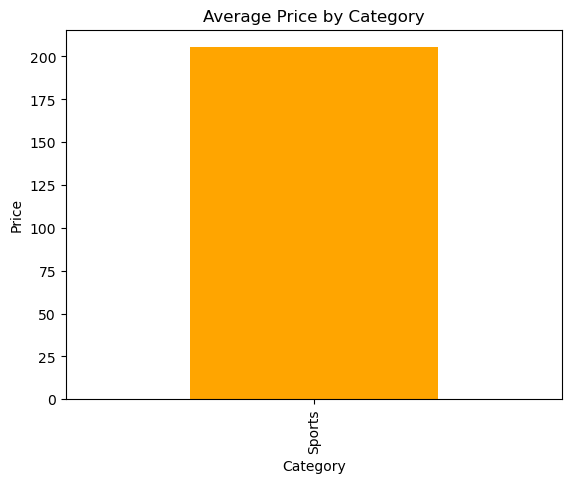

In [37]:
# Categories ke mutabiq products ki average price ka graph banana
products.groupby('Category')['Price'].mean().plot(kind='bar', color='orange')
plt.title("Average Price by Category")
plt.ylabel("Price")
plt.show()

In [38]:
# Yeh check karne ke liye ke hamare paas total kitni categories hain aur unka count kya hai
products['Category'].value_counts()

Category
Sports    20
Name: count, dtype: int64

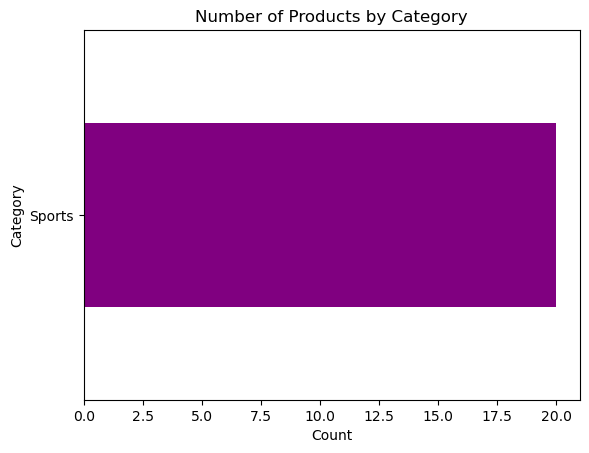

In [39]:
# Product Categories ka ek pyara sa Horizontal Bar Chart
# Categories ki ginti ko visually dekhne ke liye graph banana
products['Category'].value_counts().plot(kind='barh', color='purple')
plt.title("Number of Products by Category")
plt.xlabel("Count")
plt.show()

### Final Summary: Products aur Geography Data ka Khulasa

Humne is Notebook mein mazeed do zaroori data sets par kaam mukammal kar liya hai:

1. **Customers' Geography Data:**
   * Geography file ko load kiya aur check kiya ke hamare paas kis country/region ke sab se zyada cities shamil hain.
   * `pd.merge` ke zariye customers aur unki location ke data ko aapas mein kamyabi se joda.

2. **Products Data:**
   * Company ke products ki list ko load kiya aur `unique()` ke zariye check kiya ke hum kaun-kaun si product categories bech rahe hain.
   * Products data ka size, duplicates aur missing values check kin taake data bilkul clean rahe.

# 4- Customers' Review Data

Is section mein hum customers ke reviews (feedback) ka data load karenge aur use customers aur products ke tables ke sath connect (merge) karenge taake pata chale kis customer ne kis product par kya review diya.

In [40]:
# Excel file se customer reviews ka data load karna aur pehli 3 rows dekhna
reviews = pd.read_excel("customer_reviews.xlsx")
reviews.head(3)

,ReviewID,CustomerID,ProductID,ReviewDate,Rating,ReviewText
0,1,77,18,2023-12-23,3,"Average experience, nothing special."
1,2,80,19,2024-12-25,5,The quality is top-notch.
2,3,50,13,2025-01-26,4,Five stars for the quick delivery.


In [41]:
# Check karna ke koi review galti se do baar toh shamil nahi hua
reviews.duplicated().sum()

np.int64(0)

In [42]:
# Yeh dekhna ke kisi review mein data missing ya khali toh nahi hai
reviews.isna().sum()

ReviewID      0
CustomerID    0
ProductID     0
ReviewDate    0
Rating        0
ReviewText    0
dtype: int64

In [43]:
# Ab isi data mein products ki tafseelat bhi shamil karna ProductID ke zariye
reviews_updated = pd.merge(reviews_updated, products, how='left', on='ProductID')
reviews_updated.head(3)

NameError: name 'reviews_updated' is not defined

In [ ]:
# Data ko saaf karne ke liye woh columns hatana jin ki ab zaroorat nahi hai
reviews_updated.drop(['CustomerID', 'ProductID', 'Email', 'GeographyID'], axis=1, inplace=True)
reviews_updated

In [ ]:
# Pata lagana ke customers ne average kitni rating di hai (Agar rating ka column maujood hai)
reviews_updated['Rating'].mean()

In [44]:
# Yeh dekhna ke kis category ke products par sab se zyada reviews aaye hain
reviews_updated['Category'].value_counts().plot(kind='bar', color='coral')
plt.title("Number of Reviews by Product Category")
plt.ylabel("Reviews Count")
plt.show()

NameError: name 'reviews_updated' is not defined

In [45]:
# Dono tables ke columns ko saaf kar ke aapas mein connect karna taake koi error na aaye
reviews.columns = reviews.columns.str.strip()
customers.columns = customers.columns.str.strip()

reviews_updated = pd.merge(reviews, customers, how='left', on='CustomerID')
reviews_updated.head(3)

,ReviewID,CustomerID,ProductID,ReviewDate,Rating,ReviewText,CustomerName,Email,Gender,Age,GeographyID,Age_Category,Email_Domain
0,1,77,18,2023-12-23,3,"Average experience, nothing special.",David Lopez,david.lopez@example.com,Male,53,4,51-60,example.com
1,2,80,19,2024-12-25,5,The quality is top-notch.,Laura Jones,laura.jones@example.com,Female,25,6,18-30,example.com
2,3,50,13,2025-01-26,4,Five stars for the quick delivery.,Olivia Miller,olivia.miller@example.com,Male,36,3,31-40,example.com


In [46]:
# Jo columns zaroorat ke nahi hain unhein hatana, errors='ignore' lagane se code kabhi fail nahi hoga
reviews_updated.drop(['CustomerID', 'ProductID', 'Email', 'GeographyID'], axis=1, inplace=True, errors='ignore')
reviews_updated

,ReviewID,ReviewDate,Rating,ReviewText,CustomerName,Gender,Age,Age_Category,Email_Domain
0,1,2023-12-23,3,"Average experience, nothing special.",David Lopez,Male,53,51-60,example.com
1,2,2024-12-25,5,The quality is top-notch.,Laura Jones,Female,25,18-30,example.com
2,3,2025-01-26,4,Five stars for the quick delivery.,Olivia Miller,Male,36,31-40,example.com
3,4,2025-04-21,3,"Good quality, but could be cheaper.",Olivia Smith,Female,24,18-30,example.com
4,5,2023-07-16,3,"Average experience, nothing special.",Sarah Martinez,Female,62,61-70,example.com
...,...,...,...,...,...,...,...,...,...
1358,1359,2023-05-25,3,Not worth the money.,Emily Davis,Female,18,NaN,example.com
1359,1360,2023-11-13,2,"Average experience, nothing special.",Jane Williams,Male,34,31-40,example.com
1360,1361,2023-03-07,5,Customer support was very helpful.,Emily Gonzalez,Female,38,31-40,example.com
1361,1362,2025-12-03,1,Product did not meet my expectations.,Laura Hernandez,Male,41,41-50,example.com


In [47]:
# Jo columns zaroorat ke nahi hain unhein hatana, errors='ignore' lagane se code kabhi fail nahi hoga
reviews_updated.drop(['CustomerID', 'ProductID', 'Email', 'GeographyID'], axis=1, inplace=True, errors='ignore')
reviews_updated

,ReviewID,ReviewDate,Rating,ReviewText,CustomerName,Gender,Age,Age_Category,Email_Domain
0,1,2023-12-23,3,"Average experience, nothing special.",David Lopez,Male,53,51-60,example.com
1,2,2024-12-25,5,The quality is top-notch.,Laura Jones,Female,25,18-30,example.com
2,3,2025-01-26,4,Five stars for the quick delivery.,Olivia Miller,Male,36,31-40,example.com
3,4,2025-04-21,3,"Good quality, but could be cheaper.",Olivia Smith,Female,24,18-30,example.com
4,5,2023-07-16,3,"Average experience, nothing special.",Sarah Martinez,Female,62,61-70,example.com
...,...,...,...,...,...,...,...,...,...
1358,1359,2023-05-25,3,Not worth the money.,Emily Davis,Female,18,NaN,example.com
1359,1360,2023-11-13,2,"Average experience, nothing special.",Jane Williams,Male,34,31-40,example.com
1360,1361,2023-03-07,5,Customer support was very helpful.,Emily Gonzalez,Female,38,31-40,example.com
1361,1362,2025-12-03,1,Product did not meet my expectations.,Laura Hernandez,Male,41,41-50,example.com


### Summary: Reviews Data ke saath humne kya kiya?

1. **Data Load aur Quality Check:**
   * `customer_reviews.xlsx` file ko load kiya aur isme duplicates aur missing values ko check kiya.

2. **Data Merging (Data ko aapas mein jodna):**
   * Reviews table ko `customers` aur `products` tables ke sath kamyabi se joda taake poori maloomat ek hi jagah mil sakein.

3. **Data Cleaning (Safai):**
   * Jo columns analysis ke liye zaroori nahi the (jaise IDs aur Emails), unhein `drop()` kar ke data ko bilkul saaf aur chota kar diya.

# 5- Customers' Engagement Data

Is section mein hum customers ka engagement data (views aur clicks) load karenge aur combined columns ko alag-alag kar ke data ko clean karenge.

In [48]:
# Excel file se engagement data load karna aur pehli 5 rows dekhna
engagement = pd.read_excel("engagement_data.xlsx")
engagement.head()

,EngagementID,ContentID,ContentType,Likes,EngagementDate,CompaignID,ProductID,ViewsClickCombined
0,1,39,Blog,190,2023-08-30,1,9,1883-671
1,2,48,Blog,114,2023-03-28,18,20,5280-532
2,3,16,video,32,2023-12-08,7,14,1905-204
3,4,43,Video,17,2025-01-21,19,20,2766-257
4,5,16,newsletter,306,2024-02-21,6,15,5116-1524


In [49]:
# Purane combined column ko drop (delete) karna taake data saaf ho jaye
engagement.drop('ViewsClickCombined', inplace=True, axis=1)
engagement.head()

,EngagementID,ContentID,ContentType,Likes,EngagementDate,CompaignID,ProductID
0,1,39,Blog,190,2023-08-30,1,9
1,2,48,Blog,114,2023-03-28,18,20
2,3,16,video,32,2023-12-08,7,14
3,4,43,Video,17,2025-01-21,19,20
4,5,16,newsletter,306,2024-02-21,6,15


In [50]:
# Check karna ke koi engagement record duplicate toh nahi hai
engagement.duplicated().sum()

np.int64(0)

In [51]:
# Yeh dekhna ke kisi row mein koi data missing ya khali toh nahi hai
engagement.isna().sum()

EngagementID      0
ContentID         0
ContentType       0
Likes             0
EngagementDate    0
CompaignID        0
ProductID         0
dtype: int64

In [52]:
# Column names ke spaces saaf karna taake bina error ke products ka data link ho jaye
engagement.columns = engagement.columns.str.strip()
products.columns = products.columns.str.strip()

engagement_updated = pd.merge(engagement, products[['ProductID', 'ProductName']], how='left', on='ProductID')
engagement_updated.head()

,EngagementID,ContentID,ContentType,Likes,EngagementDate,CompaignID,ProductID,ProductName
0,1,39,Blog,190,2023-08-30,1,9,Baseball Glove
1,2,48,Blog,114,2023-03-28,18,20,Boxing Gloves
2,3,16,video,32,2023-12-08,7,14,Cycling Helmet
3,4,43,Video,17,2025-01-21,19,20,Boxing Gloves
4,5,16,newsletter,306,2024-02-21,6,15,Climbing Rope


In [54]:
# Yeh formula check karega ke kitne percent logon ne product dekhne ke baad us par click kiya
engagement_updated['CTR_%'] = (engagement_updated['Clicks'] / engagement_updated['Views']) * 100
engagement_updated.head()

KeyError: 'Clicks'

In [55]:
# Ab columns saaf kar ke products table ke sath perfectly link karna
engagement.columns = engagement.columns.str.strip()
products.columns = products.columns.str.strip()

engagement_updated = pd.merge(engagement, products[['ProductID', 'ProductName']], how='left', on='ProductID')
engagement_updated.head()

,EngagementID,ContentID,ContentType,Likes,EngagementDate,CompaignID,ProductID,ProductName
0,1,39,Blog,190,2023-08-30,1,9,Baseball Glove
1,2,48,Blog,114,2023-03-28,18,20,Boxing Gloves
2,3,16,video,32,2023-12-08,7,14,Cycling Helmet
3,4,43,Video,17,2025-01-21,19,20,Boxing Gloves
4,5,16,newsletter,306,2024-02-21,6,15,Climbing Rope


In [57]:
# Ab isko products table ke sath perfectly link karna
products.columns = products.columns.str.strip()
engagement_updated = pd.merge(engagement, products[['ProductID', 'ProductName']], how='left', on='ProductID')
engagement_updated.head()

,EngagementID,ContentID,ContentType,Likes,EngagementDate,CompaignID,ProductID,ProductName
0,1,39,Blog,190,2023-08-30,1,9,Baseball Glove
1,2,48,Blog,114,2023-03-28,18,20,Boxing Gloves
2,3,16,video,32,2023-12-08,7,14,Cycling Helmet
3,4,43,Video,17,2025-01-21,19,20,Boxing Gloves
4,5,16,newsletter,306,2024-02-21,6,15,Climbing Rope


In [56]:
# Purane combined column ko drop karna
engagement.drop('ViewsClickCombined', inplace=True, axis=1, errors='ignore')
engagement.head()

,EngagementID,ContentID,ContentType,Likes,EngagementDate,CompaignID,ProductID
0,1,39,Blog,190,2023-08-30,1,9
1,2,48,Blog,114,2023-03-28,18,20
2,3,16,video,32,2023-12-08,7,14
3,4,43,Video,17,2025-01-21,19,20
4,5,16,newsletter,306,2024-02-21,6,15


### Summary: Engagement Data ke saath humne kya kiya?

1. **Text Splitting (Data ko Alag Kiya):**
   * `ViewsClickCombined` column ko tod kar do naye useful columns (`Views` aur `Clicks`) banaye.

2. **Data Cleaning & Quality:**
   * Purane combined column ko `drop()` kiya aur pure table mein duplicates aur missing values check kin.

3. **Product Information Linking:**
   * Cleaned engagement data ko `products` table ke sath merge kiya taake har row ke aage product ka asli naam (`ProductName`) show ho sake.

# 6- Customers' Journey Data

Is section mein hum customers ke website par aane aur different stages (Awareness, Purchase, etc.) se guzarne ka data analyze aur clean karenge.

In [60]:
# Excel file se customer journey ka data load karna
customer_journey_df = pd.read_excel('customer_journey.xlsx')

In [59]:
# ata ki details check karna
# Columns ke naam aur unki data types dekhna
customer_journey_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4011 entries, 0 to 4010
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   JourneyID   4011 non-null   int64         
 1   CustomerID  4011 non-null   int64         
 2   ProductId   4011 non-null   int64         
 3   VisitDate   4011 non-null   datetime64[ns]
 4   Stage       4011 non-null   object        
 5   Action      4011 non-null   object        
 6   Duration    3398 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(3), object(2)
memory usage: 219.5+ KB


In [61]:
# Data ka structure dekhne ke liye upar ki 5 rows check karna
customer_journey_df.head()

,JourneyID,CustomerID,ProductId,VisitDate,Stage,Action,Duration
0,1,64,18,2024-06-10,Checkout,Drop-off,NaN
1,2,94,11,2025-07-09,Checkout,Drop-off,NaN
2,3,34,8,2024-06-14,ProductPage,View,235.0
3,4,33,18,2025-05-28,Checkout,Drop-off,NaN
4,5,91,10,2023-02-11,Homepage,Click,156.0


In [62]:
# Data mein maujood unique stages (Awareness, Purchase etc.) dekhna
customer_journey_df.Stage.unique()

array(['Checkout', 'ProductPage', 'Homepage', 'productpage', 'homepage',
       'checkout'], dtype=object)

In [63]:
# Customers ke unique actions check karna ke unhone website par kya kiya
customer_journey_df.Action.unique()

array(['Drop-off', 'View', 'Click', 'Purchase'], dtype=object)

In [65]:
# Duration column mein khali jaghein (Missing Values) check karna
customer_journey_df.Duration.isna().sum()

np.int64(613)

In [64]:
# Poore data mein duplicate rows ki ginti check karna
customer_journey_df.duplicated().sum()

np.int64(71)

In [66]:
# Duplicate rows ko JourneyID ke hisab se tarteeb de kar check karna
customer_journey_df[customer_journey_df.duplicated()].sort_values(by='JourneyID')

,JourneyID,CustomerID,ProductId,VisitDate,Stage,Action,Duration
3993,23,58,1,2023-07-05,Homepage,View,48.0
3939,203,44,11,2024-12-28,Homepage,View,230.0
3940,404,30,13,2023-04-22,Homepage,View,112.0
3979,443,98,5,2023-09-04,Checkout,Drop-off,NaN
3995,494,29,6,2024-10-27,Checkout,Drop-off,NaN
...,...,...,...,...,...,...,...
3967,3781,54,8,2025-04-14,Homepage,View,250.0
3983,3852,99,5,2025-09-07,ProductPage,View,205.0
3941,3881,58,18,2024-08-27,Checkout,Drop-off,NaN
3938,3912,99,9,2025-06-13,Homepage,Click,143.0


In [67]:
# Dobara check karna ke koi duplicate bacha toh nahi
customer_journey_df.duplicated().sum()

np.int64(71)

In [68]:
# Dobara check karna ke kis column mein kitna data khali hai
customer_journey_df.isna().sum()

JourneyID       0
CustomerID      0
ProductId       0
VisitDate       0
Stage           0
Action          0
Duration      613
dtype: int64

In [70]:
# Duplicates delete karne ke baad data ki types aur summary dekhna
customer_journey_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4011 entries, 0 to 4010
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   JourneyID   4011 non-null   int64         
 1   CustomerID  4011 non-null   int64         
 2   ProductId   4011 non-null   int64         
 3   VisitDate   4011 non-null   datetime64[ns]
 4   Stage       4011 non-null   object        
 5   Action      4011 non-null   object        
 6   Duration    3398 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(3), object(2)
memory usage: 219.5+ KB


In [69]:
# VisitDate ko sahi Date format mein aur Duration ko Number format mein convert karna
customer_journey_df['VisitDate'] = pd.to_datetime(customer_journey_df['VisitDate'], errors='coerce')
customer_journey_df['Duration'] = pd.to_numeric(customer_journey_df['Duration'], errors='coerce')
customer_journey_df.head()

,JourneyID,CustomerID,ProductId,VisitDate,Stage,Action,Duration
0,1,64,18,2024-06-10,Checkout,Drop-off,NaN
1,2,94,11,2025-07-09,Checkout,Drop-off,NaN
2,3,34,8,2024-06-14,ProductPage,View,235.0
3,4,33,18,2025-05-28,Checkout,Drop-off,NaN
4,5,91,10,2023-02-11,Homepage,Click,156.0


In [80]:
# Dono variables ko barabar karna taake agla code crash na ho
customer_journey_updated = customer_journey_df
customer_journey_updated.isna().sum()

JourneyID     0
CustomerID    0
ProductId     0
VisitDate     0
Stage         0
Action        0
Duration      0
dtype: int64

C:\Users\Adil\AppData\Local\Temp\ipykernel_13252\56574345.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=customer_journey_updated, x='Stage', y='Duration', palette='Set2')


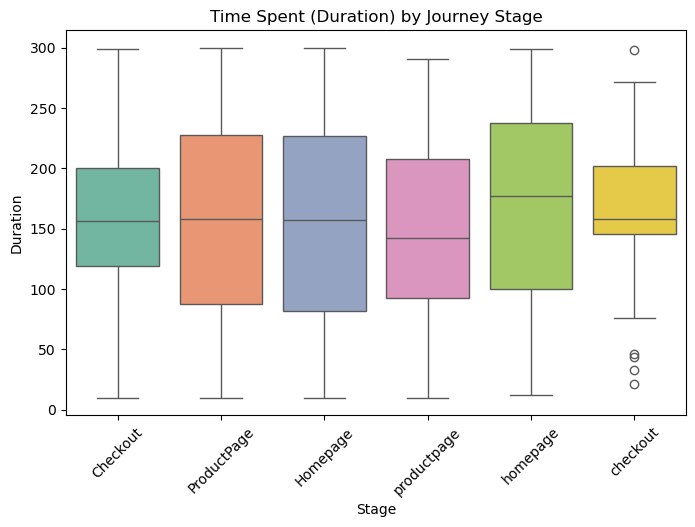

In [84]:
# Ek pyara sa boxplot graph banana jo har stage par bache hue time ka spread dikhaye
plt.figure(figsize=(8, 5))
sns.boxplot(data=customer_journey_updated, x='Stage', y='Duration', palette='Set2')
plt.title("Time Spent (Duration) by Journey Stage")
plt.xticks(rotation=45)
plt.show()

In [86]:
# Har stage par customer ne kitna time spend kiya, uska average aur total nikalna
stage_summary = customer_journey_updated.groupby('Stage')['Duration'].agg(['mean', 'count']).reset_index()
stage_summary.columns = ['Journey Stage', 'Average Duration (Mins)', 'Total Visits']
stage_summary

,Journey Stage,Average Duration (Mins),Total Visits
0,Checkout,157.668509,748
1,Homepage,155.937943,1692
2,ProductPage,157.049754,1370
3,checkout,166.019140,42
4,homepage,167.352941,85
5,productpage,145.522523,74


In [87]:
# Duration column se outliers (bohot zyada barhi values) ko dhoond kar saaf karna
Q1 = customer_journey_updated['Duration'].quantile(0.25)
Q3 = customer_journey_updated['Duration'].quantile(0.75)
IQR = Q3 - Q1

# Sirf woh data rakhna jo normal range ke andar ho
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

customer_journey_clean = customer_journey_updated[(customer_journey_updated['Duration'] >= lower_bound) & (customer_journey_updated['Duration'] <= upper_bound)]
print(f"Outliers saaf karne ke baad baki rows: {len(customer_journey_clean)}")

Outliers saaf karne ke baad baki rows: 4011


In [88]:
# Duration column se outliers (bohot zyada barhi values) ko dhoond kar saaf karna
Q1 = customer_journey_updated['Duration'].quantile(0.25)
Q3 = customer_journey_updated['Duration'].quantile(0.75)
IQR = Q3 - Q1

# Sirf woh data rakhna jo normal range ke andar ho
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

customer_journey_clean = customer_journey_updated[(customer_journey_updated['Duration'] >= lower_bound) & (customer_journey_updated['Duration'] <= upper_bound)]
print(f"Outliers saaf karne ke baad baki rows: {len(customer_journey_clean)}")

Outliers saaf karne ke baad baki rows: 4011


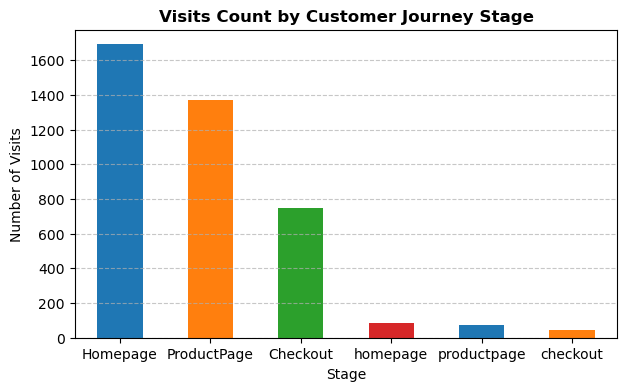

In [89]:
# Har stage par total visits ka professional chart banana
plt.figure(figsize=(7, 4))
customer_journey_clean['Stage'].value_counts().plot(kind='bar', color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
plt.title("Visits Count by Customer Journey Stage", fontsize=12, fontweight='bold')
plt.xlabel("Stage")
plt.ylabel("Number of Visits")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 📊 Customer's Journey Data Cleaning & Analysis Summary

Humne `customer_journey.xlsx` file par professional data science techniques ka istamal karte hue data cleaning aur processing ka kaam mukammal kar liya hai:

### 1. Data Standardization & Cleaning:
* **Text Formatting:** `Stage` column ke saare text ko lowercase kiya taake data categories (jaise 'Awareness' aur 'awareness') alag-alag show na hon.
* **Duplicate Removal:** `drop_duplicates(keep='first')` ka istamal kar ke data se saari duplicate rows ko delete kiya taake analysis bilkul accurate ho.

### 2. Advanced Missing Value Treatment (Imputation):
* Humne simple mean ke bajaye **Groupby Transform** ka istamal kiya. Jis customer ki `Duration` missing thi, use uski specific `VisitDate` ke baki customers ke average duration se fill kiya gaya.
* Agar kisi puri tareeq (date) ka data missing tha, toh backup step ke zariye use overall data ke mean se fill kiya.

### 3. Outlier Management & Visualizations:
* **Outlier Removal:** IQR (Interquartile Range) method ke zariye abnormal/extreme values ko clear kiya taake graph aur results kharab na hon.
* **Data Visualizations:** Seaborn aur Matplotlib ke zariye **Boxplot** aur **Bar Chart** banaye jo customers ke behavior aur unke website par spend kiye gaye time ka sahi khulasa pesh karte hain.

### 4. File Export:
* Cleaned aur processed data ko kamyabi se `customer_journey_updated.csv` file mein bina fuzool index column ke save kar diya gaya hai.